<a href="https://colab.research.google.com/github/KhushiShah-25/Ai-Society-Assignment/blob/main/adult_income_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSET485 – AI and Society | Assignment 1
## Adult Census Income dataset – Build, Stress-test, Defend

**How to use this notebook (Google Colab):** set `ROLL_NO` in the first code cell, then *Runtime → Run all*.
Everything the report needs is printed here, saved as CSV/PNG in `outputs/`, and collected in `outputs/key_numbers.json`.
The last cell zips `outputs/` and downloads it.

Sections: 0 Setup · 1 Data loading · 2 Preprocessing · 3 Part 1 (Build) · 4 Part 2.1 (Simpson) · 5 Part 2.2 (Omitted variable) · 6 Part 2.3 (Adversarial) · 7 Part 2.4 (Fairness) · 8 Export

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
# ==== 0. SETUP ====
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
try:
    import statsmodels.api as sm
except ImportError:
    get_ipython().system("pip install -q statsmodels")
    import statsmodels.api as sm
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200)

ROLL_NO = "1234567890"          # <<< CHANGE THIS to your real roll number (last digit 6-9 => Adult dataset)
SEED = int(ROLL_NO[-3:])        # last 3 digits = random_state, as the assignment requires
np.random.seed(SEED)

OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
KEY = {}                        # every headline number is stored here -> outputs/key_numbers.json
def show_save(df, name, index=True):
    df.to_csv(f"{OUT}/{name}.csv", index=index); display(df)
print("ROLL_NO:", ROLL_NO, "| random_state =", SEED)

ROLL_NO: 1234567890 | random_state = 890


## 1. Load data

In [2]:
COLS = ["age","workclass","fnlwgt","education","education-num","marital-status","occupation","relationship",
        "race","sex","capital-gain","capital-loss","hours-per-week","native-country","income"]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

def load_adult():
    if os.path.exists("adult.data"):                       # optional: upload adult.data to Colab yourself
        return pd.read_csv("adult.data", names=COLS, skipinitialspace=True)
    try:
        return pd.read_csv(URL, names=COLS, skipinitialspace=True)
    except Exception as e:                                  # fallback if UCI is down
        print("UCI download failed, using OpenML copy of the same dataset:", e)
        from sklearn.datasets import fetch_openml
        d = fetch_openml("adult", version=2, as_frame=True).frame.rename(columns={"class": "income"})
        return d[COLS]

raw = load_adult()
print(raw.shape); display(raw.head())
KEY["n_rows_raw"] = int(len(raw))

(32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Data preprocessing (document all of this in the PDF)
| Issue | Decision |
|---|---|
| Missing values | `?` in workclass / occupation / native-country is converted to NaN, counted, then filled with an explicit **"Unknown"** category (keeps all rows; missingness is not random so dropping would bias the sample). |
| Redundant / non-predictive columns | `fnlwgt` (census sampling weight), `education` (duplicate of `education-num`) and `relationship` (near-duplicate of marital-status + sex) are dropped. |
| Rare, perfectly separated categories | `Never-worked` and `Without-pay` (21 rows, none earn >50K) are merged into "Unknown" so logistic regression does not diverge. |
| Categorical encoding | One-hot encoding of workclass, marital-status, occupation, race with reference categories (Private, Never-married, Other-service, White). `sex` -> `sex_male`, `native-country` -> `native_US`. |
| Outliers | `age` and `hours-per-week` clipped (winsorised) at the 1st/99th percentile of the **training** set; heavily skewed `capital-gain/loss` are `log1p` transformed. |
| Scaling | `StandardScaler` (fit on **train only**, applied to test) on the 5 numeric columns. |
| Split | 70/30, `random_state` = last 3 digits of roll number, stratified on the target. |

In [3]:
df = raw.copy()
for c in df.select_dtypes(include=["object", "category"]).columns:
    df[c] = df[c].astype(str).str.strip()
df = df.replace({"?": np.nan, "nan": np.nan})

# --- missing values
miss = df.isna().sum(); miss = miss[miss > 0]
print("Missing values per column:\n", miss)
KEY["missing_counts"] = {k: int(v) for k, v in miss.items()}
KEY["n_duplicates_rows"] = int(df.duplicated().sum())
for c in ["workclass", "occupation", "native-country"]:
    df[c] = df[c].fillna("Unknown")
df["workclass"] = df["workclass"].replace({"Never-worked": "Unknown", "Without-pay": "Unknown"})

# --- target
df["y"] = df["income"].str.replace(".", "", regex=False).eq(">50K").astype(int)
KEY["base_rate_income_gt_50k"] = float(df["y"].mean())
print("Share earning >50K:", round(df["y"].mean(), 4))

# --- drop columns, tidy names
df = df.drop(columns=["income", "fnlwgt", "education", "relationship"])
df.columns = [c.replace("-", "_") for c in df.columns]
meta = df.copy()          # raw (unscaled, un-clipped) copy used for subgroups / demographics later

# --- split FIRST so all fitted preprocessing uses train data only
train_idx, test_idx = train_test_split(df.index, test_size=0.30, random_state=SEED, stratify=df["y"])
print("train:", len(train_idx), "test:", len(test_idx))
KEY["n_train"], KEY["n_test"] = int(len(train_idx)), int(len(test_idx))

# --- outliers
print("capital_gain == 99999 rows:", int((df.capital_gain == 99999).sum()), "| capital_gain>0:", int((df.capital_gain > 0).sum()))
q = df.loc[train_idx, ["age", "hours_per_week"]].quantile([0.01, 0.99])
for c in ["age", "hours_per_week"]:
    n_clip = int(((df[c] < q.loc[0.01, c]) | (df[c] > q.loc[0.99, c])).sum())
    print(f"{c}: clipped {n_clip} values to [{q.loc[0.01, c]}, {q.loc[0.99, c]}]")
    KEY[f"clipped_{c}"] = n_clip
    df[c] = df[c].clip(q.loc[0.01, c], q.loc[0.99, c])
df["capital_gain_log"] = np.log1p(df["capital_gain"])
df["capital_loss_log"] = np.log1p(df["capital_loss"])

# --- encoding
df["sex_male"] = (df["sex"] == "Male").astype(float)
df["native_US"] = (df["native_country"] == "United-States").astype(float)
dummies = pd.get_dummies(df[["workclass", "marital_status", "occupation", "race"]], dtype=float)
dummies.columns = [c.replace("-", "_").replace(" ", "_") for c in dummies.columns]
# reference categories (+ workclass_Unknown dropped because it is identical to occupation_Unknown after merging)
dummies = dummies.drop(columns=["workclass_Private", "workclass_Unknown", "marital_status_Never_married",
                                "occupation_Other_service", "race_White"])

# --- scaling (fit on train only)
NUM = ["age", "education_num", "capital_gain_log", "capital_loss_log", "hours_per_week"]
scaler = StandardScaler().fit(df.loc[train_idx, NUM])
X_num = pd.DataFrame(scaler.transform(df[NUM]), index=df.index, columns=NUM)

X = pd.concat([X_num, df[["sex_male", "native_US"]], dummies], axis=1)
X = X.loc[:, X.loc[train_idx].nunique() > 1]                    # drop zero-variance columns
Xc = sm.add_constant(X, has_constant="add")
y = df["y"]
Xtr, Xte, ytr, yte = Xc.loc[train_idx], Xc.loc[test_idx], y.loc[train_idx], y.loc[test_idx]
FEATURES = [c for c in Xc.columns if c != "const"]
print("Design matrix:", Xc.shape, "| rank:", np.linalg.matrix_rank(Xc.values), "(rank == #columns => no exact collinearity)")
print("Features:", FEATURES)

Missing values per column:
 workclass         1836
occupation        1843
native-country     583
dtype: int64
Share earning >50K: 0.2408
train: 22792 test: 9769
capital_gain == 99999 rows: 159 | capital_gain>0: 2712
age: clipped 286 values to [17.0, 74.0]
hours_per_week: clipped 503 values to [8.0, 80.0]
Design matrix: (32561, 37) | rank: 37 (rank == #columns => no exact collinearity)
Features: ['age', 'education_num', 'capital_gain_log', 'capital_loss_log', 'hours_per_week', 'sex_male', 'native_US', 'workclass_Federal_gov', 'workclass_Local_gov', 'workclass_Self_emp_inc', 'workclass_Self_emp_not_inc', 'workclass_State_gov', 'marital_status_Divorced', 'marital_status_Married_AF_spouse', 'marital_status_Married_civ_spouse', 'marital_status_Married_spouse_absent', 'marital_status_Separated', 'marital_status_Widowed', 'occupation_Adm_clerical', 'occupation_Armed_Forces', 'occupation_Craft_repair', 'occupation_Exec_managerial', 'occupation_Farming_fishing', 'occupation_Handlers_cleaners', 

## 3. Part 1 – Build
Model A = OLS on the 0/1 income label (linear probability model), thresholded at the **median of its own test predictions**.
Model B = logistic regression, thresholded at **0.5**.

,B (Logit>=0.5): low,B (Logit>=0.5): high
A (OLS>=median): low,4884,0
A (OLS>=median): high,2899,1986


,value
n_test,9769.000000
median_of_OLS_predictions,0.233434
OLS_pred_min,-0.356953
OLS_pred_max,1.178673
OLS_preds_below_0,2021.000000
OLS_preds_above_1,53.000000
logit_prob_median,0.115083
logit_prob_mean,0.244675
share_flagged_high_A_pct,50.005118
share_flagged_high_B_pct,20.329614


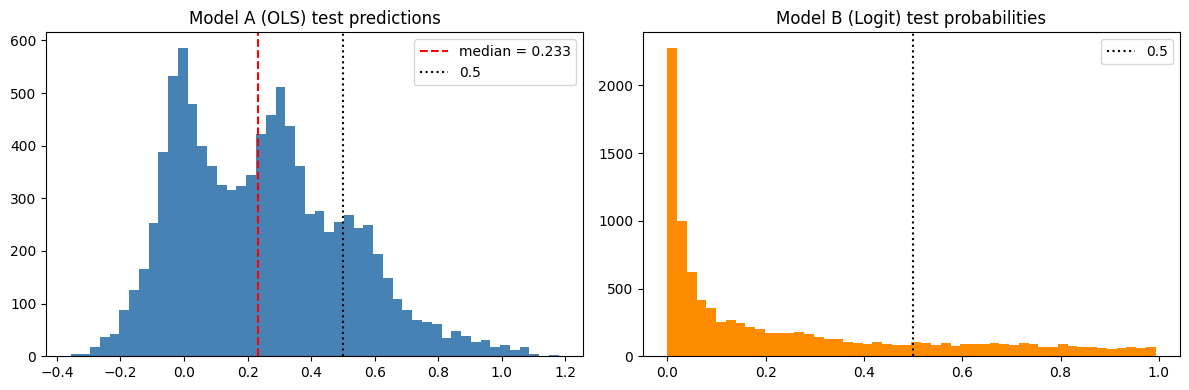

In [4]:
ols = sm.OLS(ytr, Xtr).fit()
logit = sm.Logit(ytr, Xtr).fit(disp=0, maxiter=200)

pA = ols.predict(Xte)          # Model A predictions on test
pB = logit.predict(Xte)        # Model B probabilities on test
medA = float(pA.median())
flagA = (pA >= medA).astype(int)
flagB = (pB >= 0.5).astype(int)

cm = confusion_matrix(flagA, flagB, labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["A (OLS>=median): low", "A (OLS>=median): high"],
                         columns=["B (Logit>=0.5): low", "B (Logit>=0.5): high"])
show_save(cm_df, "part1_confusion_matrix_A_vs_B")

n_test = len(yte); mismatch = int((flagA != flagB).sum())
A_only = int(((flagA == 1) & (flagB == 0)).sum()); B_only = int(((flagA == 0) & (flagB == 1)).sum())
summary = {
    "n_test": n_test,
    "median_of_OLS_predictions": medA,
    "OLS_pred_min": float(pA.min()), "OLS_pred_max": float(pA.max()),
    "OLS_preds_below_0": int((pA < 0).sum()), "OLS_preds_above_1": int((pA > 1).sum()),
    "logit_prob_median": float(pB.median()), "logit_prob_mean": float(pB.mean()),
    "share_flagged_high_A_pct": 100 * float(flagA.mean()),
    "share_flagged_high_B_pct": 100 * float(flagB.mean()),
    "mismatch_count": mismatch, "mismatch_pct": 100 * mismatch / n_test,
    "flagged_high_by_A_only": A_only, "flagged_high_by_B_only": B_only,
    "accuracy_A_vs_truth": float(accuracy_score(yte, flagA)),
    "accuracy_B_vs_truth": float(accuracy_score(yte, flagB)),
    "spearman_corr_pA_pB": float(pd.Series(pA).corr(pd.Series(pB), method="spearman")),
    "OLS_R2_train": float(ols.rsquared), "logit_pseudoR2_train": float(logit.prsquared),
    "base_rate_test": float(yte.mean()),
}
KEY["part1"] = summary
show_save(pd.Series(summary, name="value").to_frame(), "part1_summary")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pA, bins=50, color="steelblue"); ax[0].axvline(medA, color="red", ls="--", label=f"median = {medA:.3f}")
ax[0].axvline(0.5, color="black", ls=":", label="0.5"); ax[0].set_title("Model A (OLS) test predictions"); ax[0].legend()
ax[1].hist(pB, bins=50, color="darkorange"); ax[1].axvline(0.5, color="black", ls=":", label="0.5")
ax[1].set_title("Model B (Logit) test probabilities"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/part1_histograms.png", dpi=200); plt.show()

## 4. Part 2.1 – Simpson's-paradox hunt
We scan several demographic splits (sex, race, age) and two feature sets (full model, compact model). For every predictor we fit logistic regression on
(1) the whole dataset, (2) subgroup A, (3) subgroup B, and test whether the subgroup coefficients differ (z-test on the difference).
We then automatically pick the most striking case (a significant sign reversal if one exists; otherwise the largest significant difference).
You may override the choice in the `OVERRIDE` variable.

In [5]:
def fit_logit(Xd, yd):
    # keep constant + non-constant columns; drop dummies with <20 minority rows (avoids separation in small subgroups)
    keep = [c for c in Xd.columns if c == "const" or (Xd[c].nunique() > 1 and (Xd[c].nunique() > 2 or min((Xd[c] == 1).sum(), (Xd[c] == 0).sum()) >= 20))]
    try:
        return sm.Logit(yd, Xd[keep]).fit(disp=0, maxiter=200)
    except Exception as e:
        return None

COMPACT = ["age", "education_num", "hours_per_week", "capital_gain_log", "sex_male", "marital_status_Married_civ_spouse"]
FEATSETS = {"full": FEATURES, "compact": [c for c in COMPACT if c in FEATURES]}
SPLITS = {
    "sex":  (meta.sex == "Female", meta.sex == "Male", "Female", "Male", ["sex_male"]),
    "race": (meta.race == "White", meta.race != "White", "White", "Non-White", [c for c in FEATURES if c.startswith("race_")]),
    "age":  (meta.age < 40, meta.age >= 40, "age<40", "age>=40", []),
}

rows, store = [], {}
for fs_name, feats in FEATSETS.items():
    for sp, (mA, mB, lA, lB, drop_in_sub) in SPLITS.items():
        cols = ["const"] + feats
        full = fit_logit(Xc[cols], y)
        subcols = [c for c in cols if c not in drop_in_sub]
        fA, fB = fit_logit(Xc.loc[mA, subcols], y[mA]), fit_logit(Xc.loc[mB, subcols], y[mB])
        if full is None or fA is None or fB is None:
            print("skipped (did not converge):", fs_name, sp); continue
        store[(sp, fs_name)] = (full, fA, fB, lA, lB)
        ciF, ciA, ciB = full.conf_int(), fA.conf_int(), fB.conf_int()
        for c in subcols:
            if c == "const" or c not in fA.params.index or c not in fB.params.index: continue
            z = (fA.params[c] - fB.params[c]) / np.sqrt(fA.bse[c] ** 2 + fB.bse[c] ** 2)
            pdiff = 2 * (1 - norm.cdf(abs(z)))
            flip = np.sign(fA.params[c]) != np.sign(fB.params[c])
            rows.append(dict(featureset=fs_name, split=sp, groupA=lA, groupB=lB, predictor=c,
                             b_full=full.params.get(c, np.nan), full_lo=ciF.loc[c, 0] if c in ciF.index else np.nan, full_hi=ciF.loc[c, 1] if c in ciF.index else np.nan,
                             b_A=fA.params[c], A_lo=ciA.loc[c, 0], A_hi=ciA.loc[c, 1], p_A=fA.pvalues[c],
                             b_B=fB.params[c], B_lo=ciB.loc[c, 0], B_hi=ciB.loc[c, 1], p_B=fB.pvalues[c],
                             z_diff=z, p_diff=pdiff, sign_flip=flip,
                             significant_flip=bool(flip and fA.pvalues[c] < 0.05 and fB.pvalues[c] < 0.05)))
scan = pd.DataFrame(rows)
scan["abs_z"] = scan["z_diff"].abs()
scan.to_csv(f"{OUT}/part2_1_full_scan.csv", index=False)

print("Significant SIGN REVERSALS (both subgroup coefficients significant, opposite signs):")
flips = scan[scan.significant_flip].sort_values("abs_z", ascending=False)
display(flips if len(flips) else "none found")
print("Largest differences between subgroups (|z|):")
display(scan.sort_values("abs_z", ascending=False).head(12)[["featureset","split","predictor","b_full","b_A","b_B","z_diff","p_diff","sign_flip"]])

Significant SIGN REVERSALS (both subgroup coefficients significant, opposite signs):


,featureset,split,groupA,groupB,predictor,b_full,full_lo,full_hi,b_A,A_lo,A_hi,p_A,b_B,B_lo,B_hi,p_B,z_diff,p_diff,sign_flip,significant_flip,abs_z
107,compact,age,age<40,age>=40,age,0.400876,0.363969,0.437782,1.524757,1.374131,1.675384,1.337230e-87,-0.172364,-0.243491,-0.101237,0.000002,19.968709,0.0,True,True,19.968709
62,full,age,age<40,age>=40,age,0.377102,0.335153,0.419051,1.474191,1.313462,1.634919,2.967319e-72,-0.160334,-0.238575,-0.082092,0.000059,17.921234,0.0,True,True,17.921234


Largest differences between subgroups (|z|):


,featureset,split,predictor,b_full,b_A,b_B,z_diff,p_diff,sign_flip
107,compact,age,age,0.400876,1.524757,-0.172364,19.968709,0.000000,True
62,full,age,age,0.377102,1.474191,-0.160334,17.921234,0.000000,True
100,compact,sex,marital_status_Married_civ_spouse,2.307439,3.210455,1.953843,12.520679,0.000000,False
12,full,sex,marital_status_Married_civ_spouse,2.547930,3.384952,2.252071,8.325135,0.000000,False
112,compact,age,marital_status_Married_civ_spouse,2.307439,2.403944,2.006465,4.464873,0.000008,False
72,full,age,workclass_Self_emp_not_inc,-0.449269,-0.072543,-0.608146,4.108338,0.000040,False
108,compact,age,education_num,0.959856,1.020754,0.867033,3.789857,0.000151,False
111,compact,age,sex_male,0.103507,-0.028041,0.296048,-3.455079,0.000550,True
97,compact,sex,education_num,0.959856,1.111725,0.934124,3.310704,0.000931,False
67,full,age,sex_male,0.145067,-0.021695,0.313659,-3.279059,0.001042,True


CHOSEN -> split by 'age' (age<40 vs age>=40), feature set 'compact', key predictor 'age'
n(full)=32561, n(age<40)=18324, n(age>=40)=14237


,model,coef,CI_low,CI_high,p_value,odds_ratio
0,Full dataset,0.400876,0.363969,0.437782,1.434626e-100,1.493132
1,Subgroup A: age<40,1.524757,1.374131,1.675384,1.337230e-87,4.594028
2,Subgroup B: age>=40,-0.172364,-0.243491,-0.101237,2.037944e-06,0.841673


,featureset,split,groupA,groupB,predictor,b_full,full_lo,full_hi,b_A,A_lo,A_hi,p_A,b_B,B_lo,B_hi,p_B,z_diff,p_diff,sign_flip,significant_flip
107,compact,age,age<40,age>=40,age,0.4009,0.3640,0.4378,1.5248,1.3741,1.6754,0.0000,-0.1724,-0.2435,-0.1012,0.0,19.9687,0.0000,True,True
108,compact,age,age<40,age>=40,education_num,0.9599,0.9223,0.9975,1.0208,0.9562,1.0853,0.0000,0.8670,0.8207,0.9134,0.0,3.7899,0.0002,False,False
109,compact,age,age<40,age>=40,hours_per_week,0.4283,0.3928,0.4639,0.3936,0.3340,0.4531,0.0000,0.3374,0.2910,0.3838,0.0,1.4583,0.1448,False,False
110,compact,age,age<40,age>=40,capital_gain_log,0.4894,0.4594,0.5193,0.5361,0.4883,0.5839,0.0000,0.4638,0.4248,0.5028,0.0,2.2972,0.0216,False,False
111,compact,age,age<40,age>=40,sex_male,0.1035,0.0134,0.1936,-0.0280,-0.1636,0.1075,0.6851,0.2960,0.1718,0.4203,0.0,-3.4551,0.0006,True,False
112,compact,age,age<40,age>=40,marital_status_Married_civ_spouse,2.3074,2.2222,2.3927,2.4039,2.2744,2.5335,0.0000,2.0065,1.8896,2.1234,0.0,4.4649,0.0000,False,False


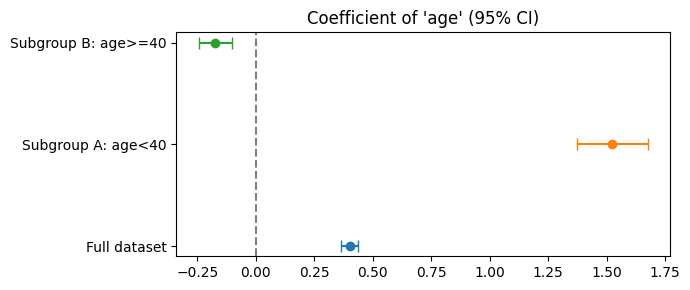

In [6]:
OVERRIDE = None     # e.g. ("sex", "full", "education_num")  -> (split, featureset, predictor); None = auto-pick
if OVERRIDE:
    sp, fs, pred = OVERRIDE
else:
    pick = (flips if len(flips) else scan).sort_values("abs_z", ascending=False).iloc[0]
    sp, fs, pred = pick["split"], pick["featureset"], pick["predictor"]
full, fA, fB, lA, lB = store[(sp, fs)]
print(f"CHOSEN -> split by '{sp}' ({lA} vs {lB}), feature set '{fs}', key predictor '{pred}'")
print(f"n(full)={int(full.nobs)}, n({lA})={int(fA.nobs)}, n({lB})={int(fB.nobs)}")

def coef_row(m, label):
    ci = m.conf_int().loc[pred]
    return dict(model=label, coef=m.params[pred], CI_low=ci[0], CI_high=ci[1], p_value=m.pvalues[pred], odds_ratio=np.exp(m.params[pred]))
t21 = pd.DataFrame([coef_row(full, "Full dataset"), coef_row(fA, f"Subgroup A: {lA}"), coef_row(fB, f"Subgroup B: {lB}")])
show_save(t21, "part2_1_chosen_predictor", index=False)
r = scan[(scan.split == sp) & (scan.featureset == fs) & (scan.predictor == pred)].iloc[0]
KEY["part2_1"] = {"split": sp, "featureset": fs, "predictor": pred, "groupA": lA, "groupB": lB,
                  "z_diff": float(r.z_diff), "p_diff": float(r.p_diff), "sign_flip": bool(r.sign_flip),
                  "table": t21.round(4).to_dict(orient="records")}

# all predictors for the chosen split (useful extra evidence)
show_save(scan[(scan.split == sp) & (scan.featureset == fs)].drop(columns=["abs_z"]).round(4), "part2_1_chosen_split_all_predictors", index=False)

# forest-style plot of the chosen predictor
fig, ax = plt.subplots(figsize=(7, 3))
for i, rr in t21.iterrows():
    ax.errorbar(rr.coef, i, xerr=[[rr.coef - rr.CI_low], [rr.CI_high - rr.coef]], fmt="o", capsize=4)
ax.set_yticks(range(3)); ax.set_yticklabels(t21.model); ax.axvline(0, color="grey", ls="--")
ax.set_title(f"Coefficient of '{pred}' (95% CI)"); plt.tight_layout(); plt.savefig(f"{OUT}/part2_1_forest.png", dpi=200); plt.show()

## 5. Part 2.2 – Omitted-variable bias
Dropped confounder: **marital status** (all `marital_status_*` dummies). It is strongly tied to income, age, sex and hours worked,
so removing it should shift those coefficients. (To test another confounder, change `DROP_PREFIX`, e.g. `"occupation_"`.)

In [7]:
DROP_PREFIX = "marital_status_"
FOCUS = ["age", "education_num", "hours_per_week", "sex_male", "capital_gain_log", "native_US"]   # >=4 predictors for the report

dropped = [c for c in FEATURES if c.startswith(DROP_PREFIX)]
red_cols = [c for c in Xc.columns if c not in dropped]
full_m = logit                                            # full model from Part 1 (train set)
red_m = sm.Logit(ytr, Xtr[red_cols]).fit(disp=0, maxiter=200)

t22 = pd.DataFrame({"coef_full": full_m.params, "coef_reduced": red_m.params}).drop(index="const").dropna()
t22["abs_change"] = t22.coef_reduced - t22.coef_full
t22["pct_change"] = 100 * (t22.coef_reduced - t22.coef_full) / t22.coef_full.abs()
t22["p_full"] = full_m.pvalues; t22["p_reduced"] = red_m.pvalues
t22 = t22.sort_values("pct_change", key=lambda s: s.abs(), ascending=False)
print("Dropped variables:", dropped)
print("\nFOCUS predictors (use in the report table):")
show_save(t22.loc[[c for c in FOCUS if c in t22.index]].round(4), "part2_2_focus_table")
print("All shared predictors, sorted by |% change|:")
show_save(t22.round(4), "part2_2_all_predictors")

top = t22.index[0]
KEY["part2_2"] = {"dropped": dropped, "largest_shift_predictor": top, "largest_shift_pct": float(t22.loc[top, "pct_change"]),
                  "focus": t22.loc[[c for c in FOCUS if c in t22.index], ["coef_full","coef_reduced","pct_change"]].round(4).to_dict(orient="index"),
                  "logit_pseudoR2_full": float(full_m.prsquared), "logit_pseudoR2_reduced": float(red_m.prsquared),
                  "test_acc_full": float(accuracy_score(yte, full_m.predict(Xte) >= .5)),
                  "test_acc_reduced": float(accuracy_score(yte, red_m.predict(Xte[red_cols]) >= .5))}
print("Largest shift:", top, round(t22.loc[top, "pct_change"], 1), "%")
print("Test accuracy full vs reduced:", KEY["part2_2"]["test_acc_full"], KEY["part2_2"]["test_acc_reduced"])

Dropped variables: ['marital_status_Divorced', 'marital_status_Married_AF_spouse', 'marital_status_Married_civ_spouse', 'marital_status_Married_spouse_absent', 'marital_status_Separated', 'marital_status_Widowed']

FOCUS predictors (use in the report table):


,coef_full,coef_reduced,abs_change,pct_change,p_full,p_reduced
age,0.3846,0.6006,0.2159,56.1297,0.0000,0.0000
education_num,0.7487,0.6681,-0.0806,-10.7666,0.0000,0.0000
hours_per_week,0.3861,0.4008,0.0147,3.7957,0.0000,0.0000
sex_male,0.0804,1.0973,1.0168,1264.1670,0.1811,0.0000
capital_gain_log,0.5028,0.4893,-0.0135,-2.6863,0.0000,0.0000
native_US,0.2299,0.1473,-0.0826,-35.9183,0.0041,0.0459


All shared predictors, sorted by |% change|:


,coef_full,coef_reduced,abs_change,pct_change,p_full,p_reduced
sex_male,0.0804,1.0973,1.0168,1264.1670,0.1811,0.0000
race_Asian_Pac_Islander,0.0035,-0.0062,-0.0097,-277.7098,0.9781,0.9572
race_Black,-0.0851,-0.2976,-0.2125,-249.6589,0.3159,0.0001
occupation_Farming_fishing,-0.0891,0.0208,0.1099,123.3206,0.6188,0.9034
workclass_Self_emp_inc,0.1920,0.3671,0.1751,91.2084,0.0553,0.0001
occupation_Machine_op_inspct,0.3823,0.6361,0.2538,66.3850,0.0095,0.0000
occupation_Handlers_cleaners,0.0772,0.1219,0.0447,57.9520,0.6773,0.4877
age,0.3846,0.6006,0.2159,56.1297,0.0000,0.0000
occupation_Unknown,0.1828,0.2842,0.1014,55.4709,0.2524,0.0601
workclass_Local_gov,-0.1952,-0.1024,0.0928,47.5585,0.0190,0.1820


Largest shift: sex_male 1264.2 %
Test accuracy full vs reduced: 0.8462483365748797 0.8294605384379159


## 6. Part 2.3 – Adversarial subset (confident wrong predictions)

In [8]:
fp = (pB >= 0.75) & (yte == 0)       # confident false positives
fn = (pB <= 0.25) & (yte == 1)       # confident false negatives
bad = fp | fn
n_bad = int(bad.sum())
print(f"Confident wrong predictions: {n_bad} of {len(yte)} test rows = {100*n_bad/len(yte):.2f}%  (false pos: {int(fp.sum())}, false neg: {int(fn.sum())})")

bad_idx = pB.index[bad]
rng = np.random.RandomState(SEED)
sub_idx = rng.choice(bad_idx, 50, replace=False) if len(bad_idx) > 50 else bad_idx
meta_te, meta_sub = meta.loc[test_idx], meta.loc[sub_idx]
print("Rows in adversarial subset:", len(sub_idx), "| false pos:", int(fp.loc[sub_idx].sum()), "| false neg:", int(fn.loc[sub_idx].sum()))

def flags(m):
    return pd.DataFrame({
        "capital_gain > 0": m.capital_gain > 0, "capital_loss > 0": m.capital_loss > 0,
        "hours >= 50": m.hours_per_week >= 50, "hours < 35": m.hours_per_week < 35,
        "age >= 50": m.age >= 50, "age < 30": m.age < 30,
        "married (civ spouse)": m.marital_status == "Married-civ-spouse",
        "male": m.sex == "Male", "white": m.race == "White",
        "bachelors or more (edu_num>=13)": m.education_num >= 13, "edu_num <= 9 (HS or less)": m.education_num <= 9,
        "exec/managerial or prof-specialty": m.occupation.isin(["Exec-managerial", "Prof-specialty"]),
        "native US": m.native_country == "United-States", "unknown occupation": m.occupation == "Unknown"})
cmp = pd.DataFrame({"adv_subset_%": flags(meta_sub).mean() * 100,
                    "false_neg_all_%": flags(meta.loc[pB.index[fn]]).mean() * 100,
                    "false_pos_all_%": flags(meta.loc[pB.index[fp]]).mean() * 100,
                    "full_test_%": flags(meta_te).mean() * 100})
cmp["subset_minus_test"] = cmp["adv_subset_%"] - cmp["full_test_%"]
cmp = cmp.sort_values("subset_minus_test", key=lambda s: s.abs(), ascending=False)
print("\nShare of rows with each trait (sorted by gap between subset and full test set):")
show_save(cmp.round(1), "part2_3_trait_comparison")

demo = pd.DataFrame({
    "adv_subset": [meta_sub.age.mean(), meta_sub.age.median(), (meta_sub.sex == "Male").mean() * 100, (meta_sub.race == "White").mean() * 100, meta_sub.hours_per_week.mean(), meta_sub.education_num.mean()],
    "full_test": [meta_te.age.mean(), meta_te.age.median(), (meta_te.sex == "Male").mean() * 100, (meta_te.race == "White").mean() * 100, meta_te.hours_per_week.mean(), meta_te.education_num.mean()]},
    index=["age mean", "age median", "% male", "% white", "hours/week mean", "education_num mean"])
show_save(demo.round(2), "part2_3_demographics")
print("Age bands (% of rows):")
bands = pd.DataFrame({"adv_subset": pd.cut(meta_sub.age, [0, 29, 39, 49, 59, 100]).value_counts(normalize=True).sort_index() * 100,
                      "full_test": pd.cut(meta_te.age, [0, 29, 39, 49, 59, 100]).value_counts(normalize=True).sort_index() * 100})
show_save(bands.round(1), "part2_3_age_bands")

top_trait = cmp.index[0]
KEY["part2_3"] = {"n_confident_wrong": n_bad, "pct_of_test": 100 * n_bad / len(yte), "n_false_pos": int(fp.sum()), "n_false_neg": int(fn.sum()),
                  "n_subset": int(len(sub_idx)), "top_trait": top_trait, "top_trait_subset_pct": float(cmp.loc[top_trait, "adv_subset_%"]),
                  "top_trait_test_pct": float(cmp.loc[top_trait, "full_test_%"]),
                  "top5_traits": cmp.head(5)[["adv_subset_%", "full_test_%"]].round(1).to_dict(orient="index")}
print("Strongest trait:", top_trait, KEY["part2_3"]["top_trait_subset_pct"], "% vs", KEY["part2_3"]["top_trait_test_pct"], "% in test")

print("\nLogit coefficients (for explaining the failure mechanism), largest |coef| first:")
coefs = pd.DataFrame({"coef": logit.params, "odds_ratio": np.exp(logit.params), "p": logit.pvalues}).drop(index="const")
show_save(coefs.sort_values("coef", key=abs, ascending=False).round(4), "part1_logit_coefficients_full_model")

Confident wrong predictions: 558 of 9769 test rows = 5.71%  (false pos: 131, false neg: 427)
Rows in adversarial subset: 50 | false pos: 18 | false neg: 32

Share of rows with each trait (sorted by gap between subset and full test set):


,adv_subset_%,false_neg_all_%,false_pos_all_%,full_test_%,subset_minus_test
married (civ spouse),68.0,51.3,94.7,46.4,21.6
age < 30,10.0,13.3,7.6,29.9,-19.9
exec/managerial or prof-specialty,42.0,22.2,65.6,25.5,16.5
male,82.0,75.4,90.1,66.8,15.2
bachelors or more (edu_num>=13),40.0,22.2,71.0,25.1,14.9
age >= 50,36.0,22.5,49.6,22.0,14.0
capital_loss > 0,18.0,5.9,13.0,4.7,13.3
edu_num <= 9 (HS or less),32.0,53.2,9.9,44.9,-12.9
hours < 35,6.0,8.2,7.6,16.6,-10.6
hours >= 50,30.0,24.6,54.2,20.0,10.0


,adv_subset,full_test
age mean,43.88,38.69
age median,41.00,37.00
% male,82.00,66.78
% white,86.00,85.00
hours/week mean,43.12,40.52
education_num mean,11.02,10.10


Age bands (% of rows):


,adv_subset,full_test
age,,
"(0, 29]",10.0,29.9
"(29, 39]",34.0,26.0
"(39, 49]",20.0,22.1
"(49, 59]",28.0,13.7
"(59, 100]",8.0,8.3


Strongest trait: married (civ spouse) 68.0 % vs 46.381410584502 % in test

Logit coefficients (for explaining the failure mechanism), largest |coef| first:


,coef,odds_ratio,p
occupation_Priv_house_serv,-20.1028,0.0000,0.9982
occupation_Armed_Forces,-16.6217,0.0000,0.9985
marital_status_Married_AF_spouse,4.1882,65.9048,0.0000
marital_status_Married_civ_spouse,2.6193,13.7261,0.0000
occupation_Exec_managerial,1.5694,4.8038,0.0000
occupation_Protective_serv,1.4235,4.1516,0.0000
occupation_Tech_support,1.3982,4.0480,0.0000
occupation_Prof_specialty,1.3332,3.7933,0.0000
occupation_Sales,1.0644,2.8992,0.0000
occupation_Craft_repair,0.8274,2.2874,0.0000


## 7. Part 2.4 – Fairness trade-off analysis
Sensitive variable: **sex** (Group A = Female, Group B = Male, so ratios are A/B). Thresholds 0.05, 0.15, …, 0.95 on Model B's test probabilities.
(Change `SENS_COL`/groups to use race instead.)

Group A = Female (n=3245), Group B = Male (n=6524)


,DP,EO,PP,TPR_ratio,FPR_ratio,sel_rate_A,sel_rate_B,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B,accuracy,accuracy_A,accuracy_B
threshold,,,,,,,,,,,,,,,,
0.05,0.6077,0.6234,0.5442,0.9835,0.6234,0.4394,0.7232,0.9674,0.9836,0.3783,0.6068,0.2286,0.4201,0.6028,0.6576,0.5756
0.15,0.3802,0.3479,0.8136,0.9199,0.3479,0.2182,0.5739,0.8546,0.9290,0.1444,0.4152,0.4068,0.5000,0.7457,0.8555,0.6911
0.25,0.3075,0.2688,0.8961,0.8194,0.2688,0.1418,0.4611,0.6884,0.8402,0.0784,0.2916,0.5043,0.5628,0.7983,0.8974,0.7491
0.35,0.2627,0.2122,0.9729,0.7602,0.2122,0.0965,0.3671,0.5727,0.7533,0.0413,0.1945,0.6166,0.6338,0.8323,0.9186,0.7894
0.45,0.2473,0.1976,0.9836,0.7235,0.1976,0.0743,0.3003,0.4837,0.6685,0.0268,0.1357,0.6763,0.6876,0.8432,0.9223,0.8038
0.55,0.2428,0.1938,0.9880,0.7134,0.1938,0.0582,0.2399,0.4125,0.5782,0.0172,0.0887,0.7354,0.7444,0.8467,0.9236,0.8084
0.65,0.2154,0.2011,0.9463,0.6062,0.2011,0.0388,0.1803,0.2819,0.4650,0.0107,0.0530,0.7540,0.7968,0.8372,0.9159,0.7981
0.75,0.1963,0.1708,0.9767,0.5703,0.1708,0.0231,0.1177,0.1840,0.3226,0.0045,0.0262,0.8267,0.8464,0.8187,0.9112,0.7727
0.85,0.1750,0.2040,0.9498,0.4944,0.2040,0.0114,0.0651,0.0950,0.1921,0.0017,0.0084,0.8649,0.9106,0.7977,0.9045,0.7446


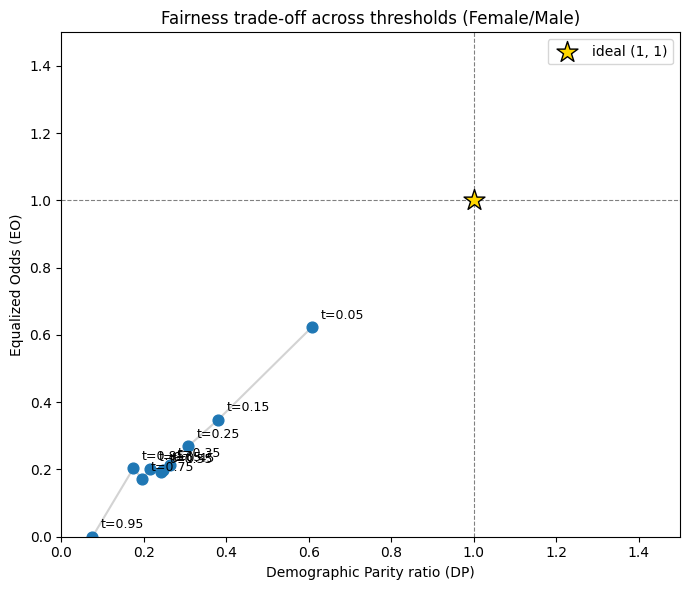

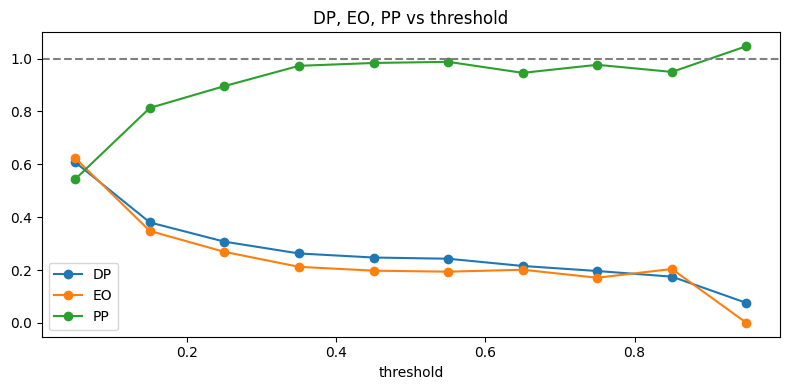

In [9]:
SENS_COL, GA, GB = "sex", "Female", "Male"
sens = meta.loc[test_idx, SENS_COL].values
gA, gB = sens == GA, sens == GB
yt, pt = yte.values, pB.values
THRESH = np.round(np.arange(0.05, 0.951, 0.10), 2)

def ratio(a, b):
    return np.nan if (b is None or np.isnan(b) or b == 0 or np.isnan(a)) else a / b
def group_stats(yh, yg):
    sel = yh.mean()
    P, N = (yg == 1).sum(), (yg == 0).sum()
    tp, fpp, pp = ((yh == 1) & (yg == 1)).sum(), ((yh == 1) & (yg == 0)).sum(), (yh == 1).sum()
    return sel, (tp / P if P else np.nan), (fpp / N if N else np.nan), (tp / pp if pp else np.nan)

rows = []
for t in THRESH:
    yh = (pt >= t).astype(int)
    sA, tprA, fprA, ppvA = group_stats(yh[gA], yt[gA]); sB, tprB, fprB, ppvB = group_stats(yh[gB], yt[gB])
    DP = ratio(sA, sB); EO = np.nanmin([ratio(tprA, tprB), ratio(fprA, fprB)]); PP = ratio(ppvA, ppvB)
    rows.append(dict(threshold=t, DP=DP, EO=EO, PP=PP, TPR_ratio=ratio(tprA, tprB), FPR_ratio=ratio(fprA, fprB),
                     sel_rate_A=sA, sel_rate_B=sB, TPR_A=tprA, TPR_B=tprB, FPR_A=fprA, FPR_B=fprB, PPV_A=ppvA, PPV_B=ppvB,
                     accuracy=accuracy_score(yt, yh), accuracy_A=accuracy_score(yt[gA], yh[gA]), accuracy_B=accuracy_score(yt[gB], yh[gB])))
tab = pd.DataFrame(rows).set_index("threshold")
print(f"Group A = {GA} (n={gA.sum()}), Group B = {GB} (n={gB.sum()})")
show_save(tab.round(4), "part2_4_fairness_table")
KEY["part2_4"] = {"groups": [GA, GB], "table": tab[["DP", "EO", "PP", "accuracy"]].round(4).to_dict(orient="index")}

# trade-off chart
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(tab.DP, tab.EO, "-", color="lightgrey", zorder=1)
ax.scatter(tab.DP, tab.EO, s=60, zorder=2)
for t, r in tab.iterrows():
    if not (np.isnan(r.DP) or np.isnan(r.EO)): ax.annotate(f"t={t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.scatter([1], [1], marker="*", s=250, color="gold", edgecolor="k", zorder=3, label="ideal (1, 1)")
ax.axvline(1, color="grey", ls="--", lw=.8); ax.axhline(1, color="grey", ls="--", lw=.8)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_xlabel("Demographic Parity ratio (DP)"); ax.set_ylabel("Equalized Odds (EO)")
ax.set_title(f"Fairness trade-off across thresholds ({GA}/{GB})"); ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/part2_4_tradeoff_chart.png", dpi=200); plt.show()
off = tab[(tab.DP > 1.5) | (tab.EO > 1.5)]
if len(off): print("NOTE: these thresholds fall outside the 0-1.5 axes:", list(off.index))

# also PP vs threshold
tab[["DP", "EO", "PP"]].plot(marker="o", figsize=(8, 4), title="DP, EO, PP vs threshold"); plt.axhline(1, color="grey", ls="--")
plt.tight_layout(); plt.savefig(f"{OUT}/part2_4_metrics_vs_threshold.png", dpi=200); plt.show()

In [10]:
# Quantify the trade-off between any two thresholds: "improve DP from X to Y (Z% gain), EO drops from A to B (W% loss); cost = W/Z"
def tradeoff(t1, t2):
    r1, r2 = tab.loc[t1], tab.loc[t2]
    dp_pct = 100 * (r2.DP - r1.DP) / r1.DP; eo_pct = 100 * (r2.EO - r1.EO) / r1.EO
    cost = abs(eo_pct) / abs(dp_pct) if dp_pct else np.nan
    print(f"Moving t={t1} -> t={t2}: DP {r1.DP:.3f} -> {r2.DP:.3f} ({dp_pct:+.1f}%), EO {r1.EO:.3f} -> {r2.EO:.3f} ({eo_pct:+.1f}%), "
          f"PP {r1.PP:.3f} -> {r2.PP:.3f}, accuracy {r1.accuracy:.3f} -> {r2.accuracy:.3f}, trade-off cost W/Z = {cost:.2f}")
    return dict(t_from=t1, t_to=t2, DP_from=r1.DP, DP_to=r2.DP, DP_pct=dp_pct, EO_from=r1.EO, EO_to=r2.EO, EO_pct=eo_pct, cost=cost)

valid = tab.dropna(subset=["DP", "EO"])
t_dp = (valid.DP - 1).abs().idxmin(); t_eo = (valid.EO - 1).abs().idxmin()
print("Threshold with DP closest to 1:", t_dp, "| threshold with EO closest to 1:", t_eo)
pairs = []
if t_dp != t_eo: pairs.append(tradeoff(t_eo, t_dp))
for a, b in zip(valid.index[:-1], valid.index[1:]): pairs.append(tradeoff(a, b))   # every consecutive step
tr = pd.DataFrame(pairs); show_save(tr.round(4), "part2_4_tradeoff_pairs", index=False)
KEY["part2_4"]["t_best_DP"], KEY["part2_4"]["t_best_EO"] = float(t_dp), float(t_eo)
KEY["part2_4"]["tradeoff_best_EO_to_best_DP"] = {k: float(v) for k, v in pairs[0].items()} if t_dp != t_eo else None
# Edit this to analyse any pair you want to discuss in the report:
CUSTOM_PAIR = (0.35, 0.55)      # <- change to the two thresholds you want to discuss
if all(t in tab.index for t in CUSTOM_PAIR): tradeoff(*CUSTOM_PAIR)

Threshold with DP closest to 1: 0.05 | threshold with EO closest to 1: 0.05
Moving t=0.05 -> t=0.15: DP 0.608 -> 0.380 (-37.4%), EO 0.623 -> 0.348 (-44.2%), PP 0.544 -> 0.814, accuracy 0.603 -> 0.746, trade-off cost W/Z = 1.18
Moving t=0.15 -> t=0.25: DP 0.380 -> 0.307 (-19.1%), EO 0.348 -> 0.269 (-22.7%), PP 0.814 -> 0.896, accuracy 0.746 -> 0.798, trade-off cost W/Z = 1.19
Moving t=0.25 -> t=0.35: DP 0.307 -> 0.263 (-14.5%), EO 0.269 -> 0.212 (-21.1%), PP 0.896 -> 0.973, accuracy 0.798 -> 0.832, trade-off cost W/Z = 1.45
Moving t=0.35 -> t=0.45: DP 0.263 -> 0.247 (-5.9%), EO 0.212 -> 0.198 (-6.9%), PP 0.973 -> 0.984, accuracy 0.832 -> 0.843, trade-off cost W/Z = 1.17
Moving t=0.45 -> t=0.55: DP 0.247 -> 0.243 (-1.8%), EO 0.198 -> 0.194 (-1.9%), PP 0.984 -> 0.988, accuracy 0.843 -> 0.847, trade-off cost W/Z = 1.05
Moving t=0.55 -> t=0.65: DP 0.243 -> 0.215 (-11.3%), EO 0.194 -> 0.201 (+3.8%), PP 0.988 -> 0.946, accuracy 0.847 -> 0.837, trade-off cost W/Z = 0.33
Moving t=0.65 -> t=0.75

,t_from,t_to,DP_from,DP_to,DP_pct,EO_from,EO_to,EO_pct,cost
0,0.05,0.15,0.6077,0.3802,-37.4344,0.6234,0.3479,-44.1958,1.1806
1,0.15,0.25,0.3802,0.3075,-19.1309,0.3479,0.2688,-22.7203,1.1876
2,0.25,0.35,0.3075,0.2627,-14.5408,0.2688,0.2122,-21.0826,1.4499
3,0.35,0.45,0.2627,0.2473,-5.8666,0.2122,0.1976,-6.8546,1.1684
4,0.45,0.55,0.2473,0.2428,-1.8331,0.1976,0.1938,-1.9231,1.0491
5,0.55,0.65,0.2428,0.2154,-11.2812,0.1938,0.2011,3.7657,0.3338
6,0.65,0.75,0.2154,0.1963,-8.8542,0.2011,0.1708,-15.0629,1.7012
7,0.75,0.85,0.1963,0.1750,-10.8518,0.1708,0.2040,19.4332,1.7908
8,0.85,0.95,0.1750,0.0756,-56.8177,0.2040,0.0000,-100.0000,1.7600


Moving t=0.35 -> t=0.55: DP 0.263 -> 0.243 (-7.6%), EO 0.212 -> 0.194 (-8.6%), PP 0.973 -> 0.988, accuracy 0.832 -> 0.847, trade-off cost W/Z = 1.14


## 8. Export everything for the report

In [11]:
def _clean(o):
    if hasattr(o, "item"): return o.item()
    return str(o)
with open(f"{OUT}/key_numbers.json", "w") as f:
    json.dump(KEY, f, indent=2, default=_clean)
print(json.dumps(KEY, indent=1, default=_clean)[:6000])

import shutil
shutil.make_archive("assignment_outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("assignment_outputs.zip")
except ImportError:
    print("Not in Colab - zip saved as assignment_outputs.zip")

{
 "n_rows_raw": 32561,
 "missing_counts": {
  "workclass": 1836,
  "occupation": 1843,
  "native-country": 583
 },
 "n_duplicates_rows": 24,
 "base_rate_income_gt_50k": 0.2408095574460244,
 "n_train": 22792,
 "n_test": 9769,
 "clipped_age": 286,
 "clipped_hours_per_week": 503,
 "part1": {
  "n_test": 9769,
  "median_of_OLS_predictions": 0.23343364283813345,
  "OLS_pred_min": -0.3569527979850964,
  "OLS_pred_max": 1.1786733254436315,
  "OLS_preds_below_0": 2021,
  "OLS_preds_above_1": 53,
  "logit_prob_median": 0.1150825378006593,
  "logit_prob_mean": 0.24467473226764827,
  "share_flagged_high_A_pct": 50.00511823113932,
  "share_flagged_high_B_pct": 20.329614085372093,
  "mismatch_count": 2899,
  "mismatch_pct": 29.675504145767224,
  "flagged_high_by_A_only": 2899,
  "flagged_high_by_B_only": 0,
  "accuracy_A_vs_truth": 0.7118435868563824,
  "accuracy_B_vs_truth": 0.8462483365748797,
  "spearman_corr_pA_pB": 0.9810415737401553,
  "OLS_R2_train": 0.37444297610387034,
  "logit_pseudoR2_t

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>